# Stage 5: Exploratory Data Visualization – TMDB Movie Analysis

## Objective

The objective of this stage is to explore the TMDB movie dataset through univariate, bivariate and multivariate visualizations. The visualizations aim to identify patterns, relationships, distributions and trends in the global movie industry.

## Libraries Used

- **Pandas:** Data manipulation and analysis.
- **NumPy:** Numerical operations.
- **Matplotlib:** Static data visualization.
- **Seaborn:** Statistical data visualization.
- **Plotly:** Interactive data visualization.

## Analysis Categories

### 1. Univariate Analysis
Exploring individual variables such as movie budgets, runtimes, ratings, popularity and genres.

### 2. Bivariate Analysis
Examining relationships between two variables, including budget and revenue, popularity and vote count, and movie ratings across genres.

### 3. Multivariate Analysis
Exploring relationships among multiple variables using correlation heatmaps, multivariate scatter plots, FacetGrids and other advanced visualizations.

## Expected Outcome

To transform the findings from the previous SQL and Pandas analysis stages into meaningful visual insights, supported by appropriate charts and interpretations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

%matplotlib inline

sns.set_theme(style="whitegrid")

In [2]:
movies_df = pd.read_csv("cleaned_data/movies.csv")
genres_df = pd.read_csv("cleaned_data/genres.csv")
movie_genres_df = pd.read_csv("cleaned_data/movie_genres.csv")
cast_df = pd.read_csv("cleaned_data/cast.csv")
crew_df = pd.read_csv("cleaned_data/crew.csv")
movie_keywords_df = pd.read_csv("cleaned_data/movie_keywords.csv")

movies_df["release_date"] = pd.to_datetime(
    movies_df["release_date"], errors="coerce"
)

print("All datasets loaded successfully!")

print("Movies:", movies_df.shape)
print("Genres:", genres_df.shape)
print("Movie Genres:", movie_genres_df.shape)
print("Cast:", cast_df.shape)
print("Crew:", crew_df.shape)
print("Movie Keywords:", movie_keywords_df.shape)

All datasets loaded successfully!
Movies: (2503, 12)
Genres: (19, 2)
Movie Genres: (6878, 2)
Cast: (24902, 6)
Crew: (7289, 6)
Movie Keywords: (41681, 3)


## 1: Distribution of Movie Budgets

**Objective:** To understand how movie budgets are distributed across different movies.

**Chart:** Histogram with KDE curve.

**Insight:** To identify the most common budget ranges and understand the spread of movie production budgets.

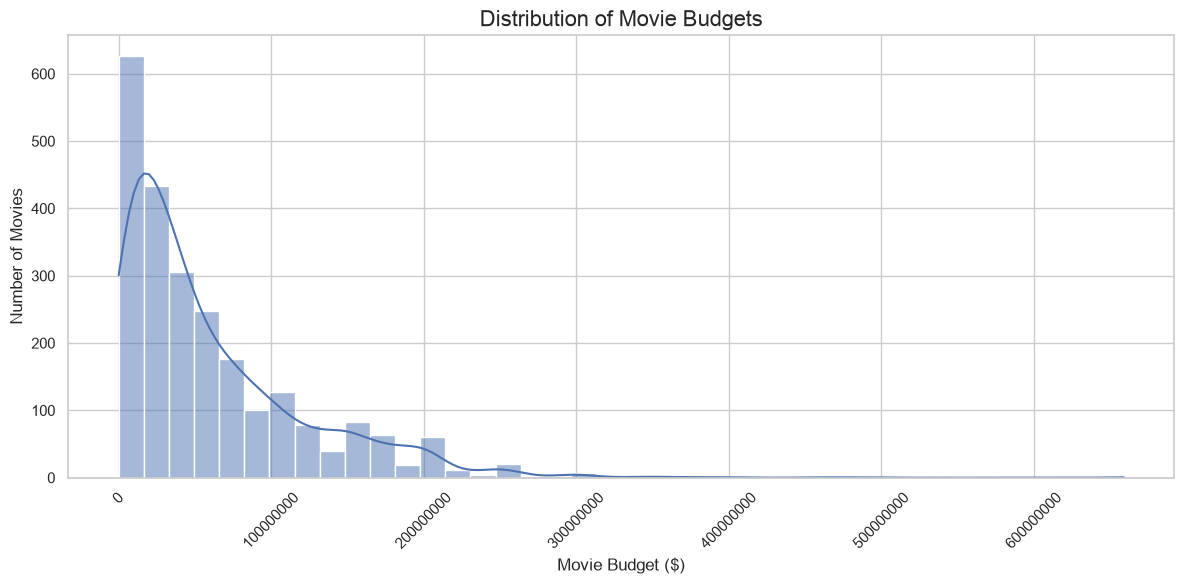

In [3]:
# Load original movie data for actual budget values
original_movies_df = pd.read_csv("data/movies.csv")

# Filter valid budget values
budget_data = original_movies_df[
    original_movies_df["budget"].notna() &
    (original_movies_df["budget"] > 0)
]["budget"]

# Create histogram with KDE
plt.figure(figsize=(12, 6))

sns.histplot(
    budget_data,
    bins=40,
    kde=True
)

plt.title("Distribution of Movie Budgets", fontsize=16)
plt.xlabel("Movie Budget ($)", fontsize=12)
plt.ylabel("Number of Movies", fontsize=12)

plt.ticklabel_format(style="plain", axis="x")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Insights

- Most movies have relatively low production budgets, with the highest concentration in the lower budget ranges.
- The number of movies decreases as production budgets increase.
- The distribution is strongly right-skewed, indicating that only a small number of movies have extremely high budgets.
- A few movies have budgets exceeding $300 million, making them extreme values compared to most movies.

### Conclusion

Most movies in the dataset are produced with relatively modest budgets, while a small number of big-budget productions create a long right tail in the distribution.

##  2: Distribution of Movie Runtimes

**Objective:** To understand how movie runtimes are distributed across the dataset and identify unusually short or long movies.

**Chart:** Box plot.

**Insight:** To identify the typical movie runtime, the spread of runtimes and potential outliers.

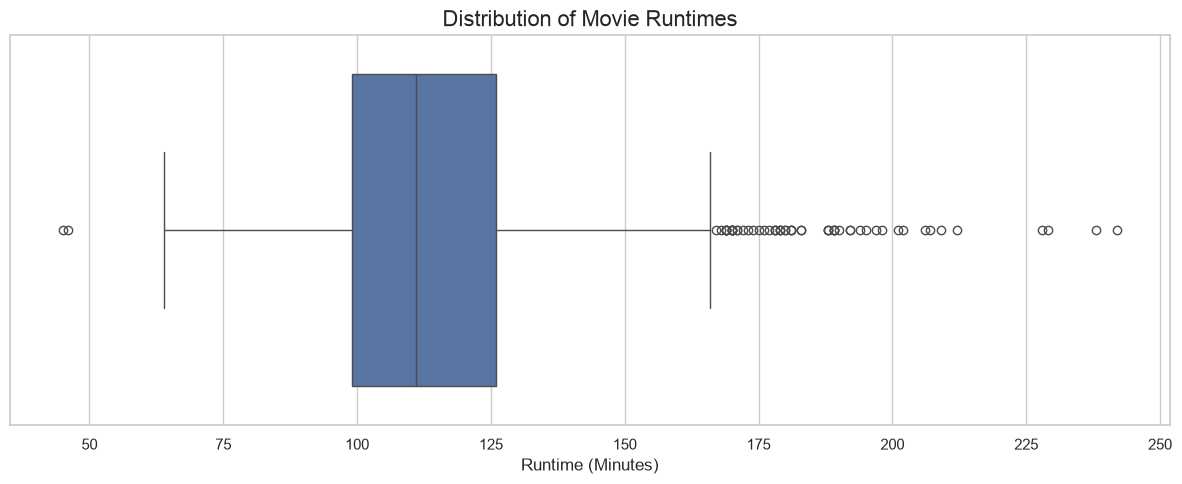

In [4]:
plt.figure(figsize=(12, 5))

sns.boxplot(x=movies_df["runtime"].dropna())

plt.title("Distribution of Movie Runtimes", fontsize=16)
plt.xlabel("Runtime (Minutes)")

plt.tight_layout()
plt.show()

### Insights

- Most movies have runtimes between approximately 99 and 126 minutes.
- The median runtime is around 111 minutes.
- Several movies have runtimes above 166 minutes, which appear as outliers.
- A few movies have exceptionally long runtimes exceeding 200 minutes.
- The distribution shows a longer tail towards higher runtimes.

### Conclusion

Most movies have runtimes of approximately 1.5 to 2 hours, while a smaller number of movies have significantly longer durations.

## 3: Distribution of Movie Ratings

**Objective:** To understand how movie ratings are distributed across the dataset.

**Chart:** Histogram with KDE curve.

**Insight:** To identify the most common rating range and understand the overall rating distribution.

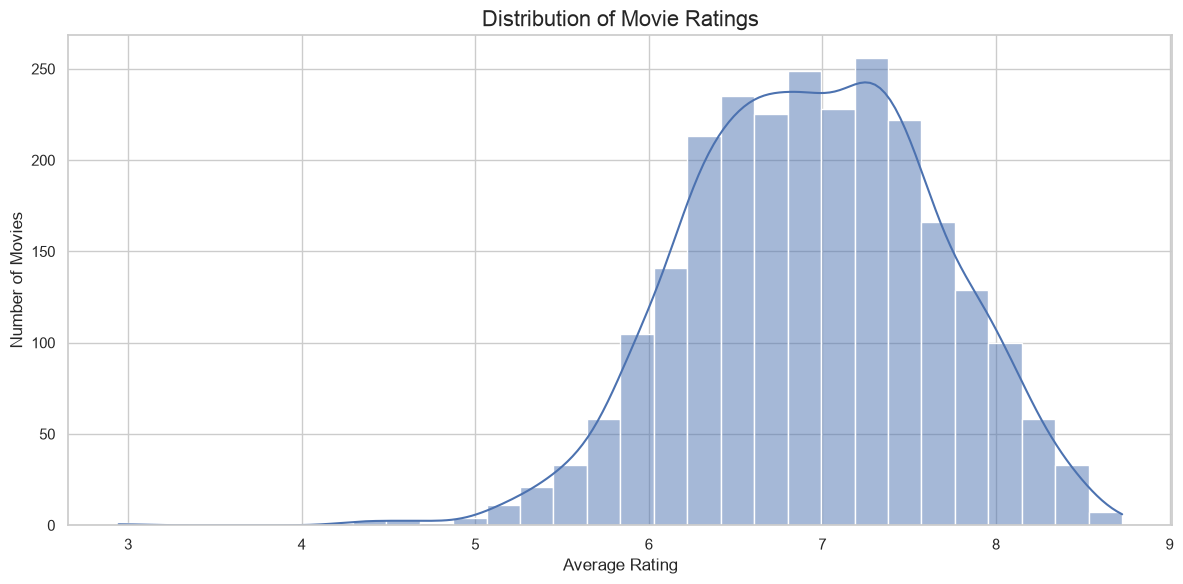

In [6]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=movies_df,
    x="vote_average",
    bins=30,
    kde=True
)

plt.title("Distribution of Movie Ratings", fontsize=16)
plt.xlabel("Average Rating")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()

### Insights

- Most movies have average ratings between 6 and 8.
- The highest concentration of movies is around ratings 7.0–7.5.
- Very few movies have ratings below 5.
- Only a small number of movies have ratings above 8.5.
- The distribution is approximately bell-shaped, with most movies receiving moderate to good ratings.

### Conclusion

Most movies in the dataset receive moderate to good audience ratings, while extremely low and exceptionally high ratings are less common.

## 4: Number of Movies per Genre

**Objective:** To compare the number of movies belonging to different genres.

**Chart:** Bar chart.

**Insight:** To identify the most and least common movie genres in the dataset.

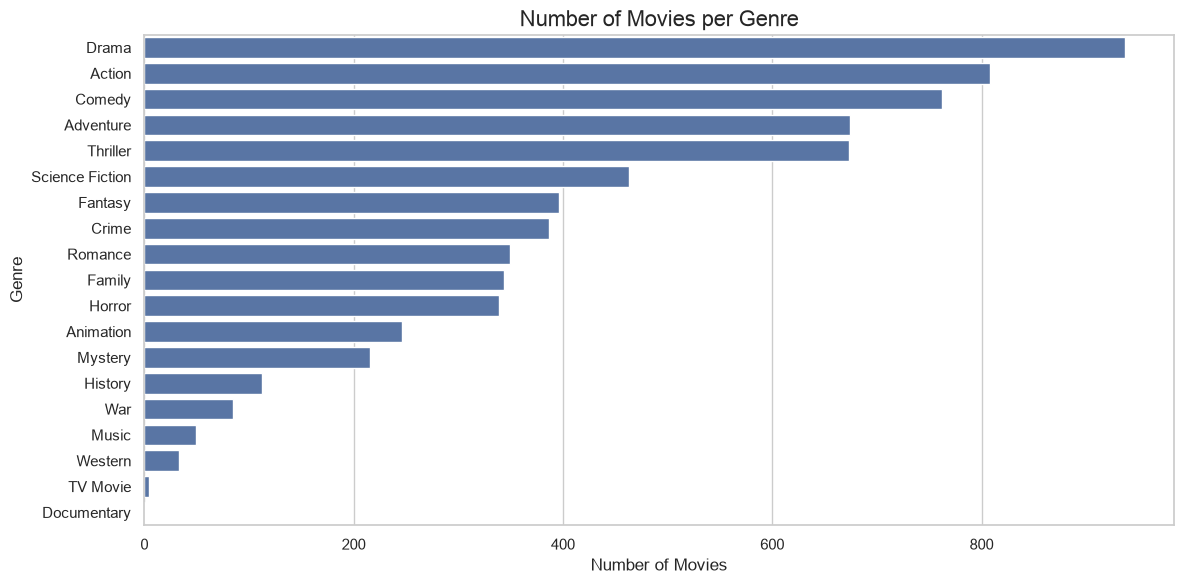

In [7]:
# Merge movie genres with genre names
genre_movies = movie_genres_df.merge(
    genres_df,
    on="genre_id",
    how="left"
)

# Count unique movies in each genre
genre_counts = (
    genre_movies.groupby("genre_name")["movie_id"]
    .nunique()
    .sort_values(ascending=False)
)

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title("Number of Movies per Genre", fontsize=16)
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

### Insights

- Drama has the highest number of movies, followed by Action and Comedy.
- Adventure and Thriller also have a strong representation in the dataset.
- Documentary, TV Movie and Western are among the least represented genres.
- The dataset contains considerably more Drama and Action movies than less common genres such as Music and War.

### Conclusion

The dataset is dominated by Drama, Action and Comedy movies, indicating that these genres have the largest representation among the movies analysed.

## 5: Distribution of Movie Popularity

**Objective:** To understand how popularity scores vary across movies.

**Chart:** Histogram with KDE curve.

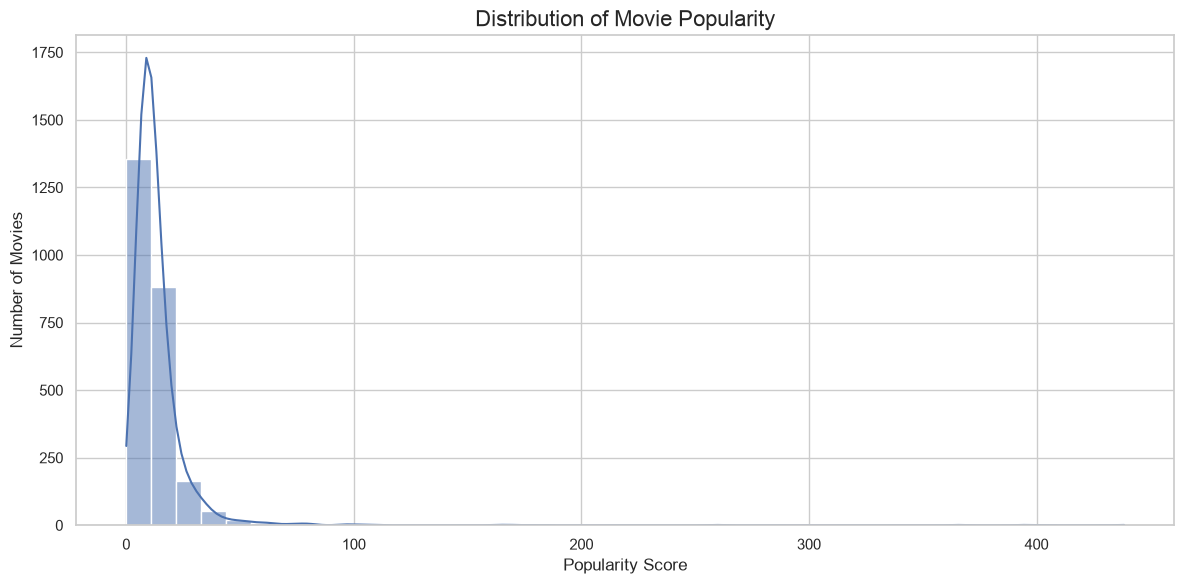

In [8]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=movies_df,
    x="popularity",
    bins=40,
    kde=True
)

plt.title("Distribution of Movie Popularity", fontsize=16)
plt.xlabel("Popularity Score")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()

### Insights

- Most movies have popularity scores concentrated below 50.
- The number of movies decreases significantly as popularity increases.
- A small number of movies have exceptionally high popularity scores, exceeding 100.
- A few extreme values extend beyond 400, creating a long right tail.
- The distribution is highly right-skewed, indicating that only a small proportion of movies achieve very high popularity.

### Conclusion

Most movies have relatively low popularity scores, while a small number attract significantly higher attention and stand out from the rest of the dataset.

## 6: Budget vs Revenue

**Objective:** To examine the relationship between movie production budgets and revenue.

**Chart:** Scatter plot with a trend line.

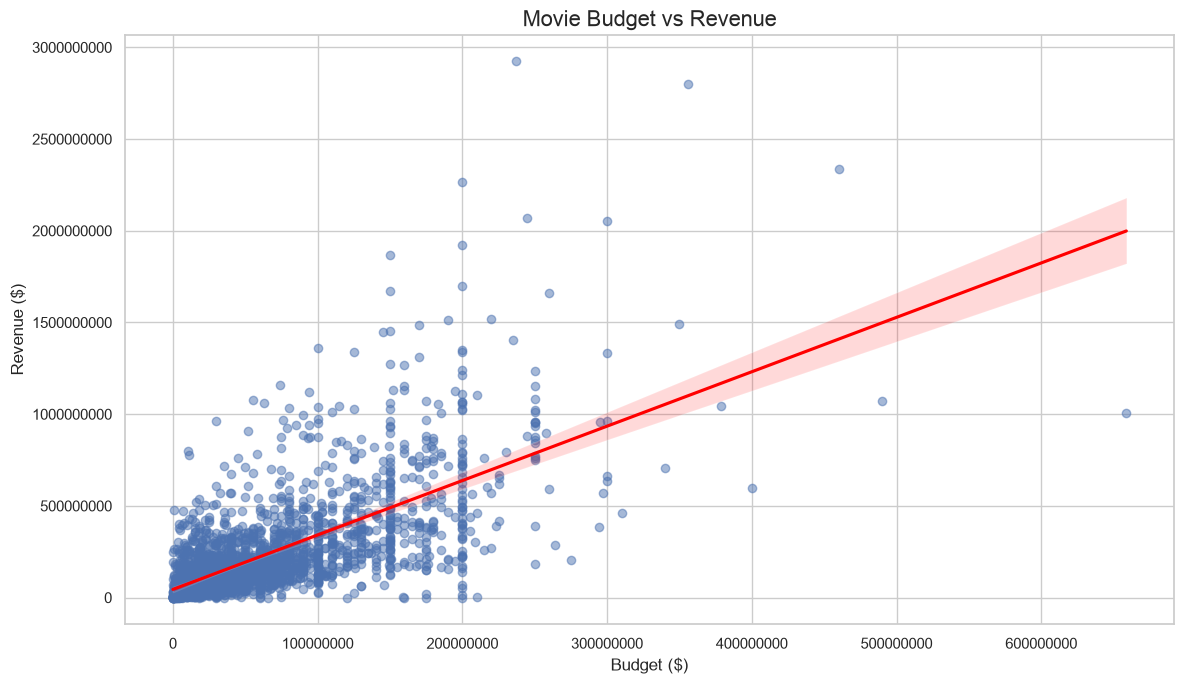

In [9]:
# Use original financial values and exclude invalid entries
financial_data = original_movies_df[
    (original_movies_df["budget"] > 0) &
    (original_movies_df["revenue"] > 0)
].copy()

plt.figure(figsize=(12, 7))

sns.regplot(
    data=financial_data,
    x="budget",
    y="revenue",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Movie Budget vs Revenue", fontsize=16)
plt.xlabel("Budget ($)")
plt.ylabel("Revenue ($)")

plt.ticklabel_format(style="plain", axis="both")
plt.tight_layout()
plt.show()

### Insights

- Movies with higher production budgets generally tend to generate higher revenues.
- Most movies are concentrated in the lower budget and revenue ranges.
- A few high-budget movies generate exceptionally high revenues.
- There is considerable variation in revenue among movies with similar budgets.
- Some movies with large budgets generate relatively low revenues, showing that higher investment does not guarantee higher earnings.

### Conclusion

Movie budget and revenue have a positive relationship, but the considerable variation suggests that production budget alone does not determine a movie's financial success.

## 7: Popularity vs Vote Count

**Objective:** To examine the relationship between movie popularity and audience vote count.

**Chart:** Scatter plot.

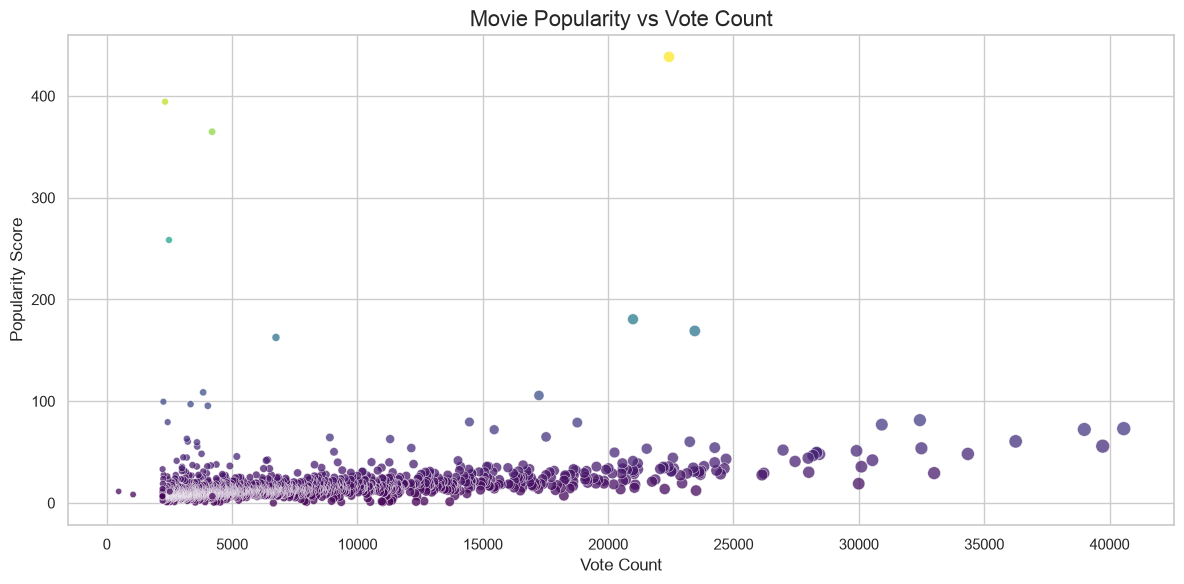

In [11]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=movies_df,
    x="vote_count",
    y="popularity",
    hue="popularity",
    palette="viridis",
    size="vote_count",
    sizes=(20, 100),
    alpha=0.75,
    legend=False
)

plt.title("Movie Popularity vs Vote Count", fontsize=16)
plt.xlabel("Vote Count")
plt.ylabel("Popularity Score")

plt.tight_layout()
plt.show()

### Insights

- Most movies are concentrated in the lower popularity and vote-count ranges.
- Movies with higher vote counts generally tend to have higher popularity scores.
- A few movies show exceptionally high popularity despite having relatively low vote counts.
- Some movies have very high vote counts but comparatively moderate popularity scores.
- The relationship is positive but not particularly strong, consistent with the correlation value of approximately 0.36.

### Conclusion

Popularity and vote count are positively related, but they do not always increase together. Some movies attract significant attention despite receiving fewer votes, while others accumulate many votes without exceptionally high popularity.

## 8: Average Rating by Genre

**Objective:** To compare the average audience ratings across different movie genres.

**Chart:** Horizontal bar chart.

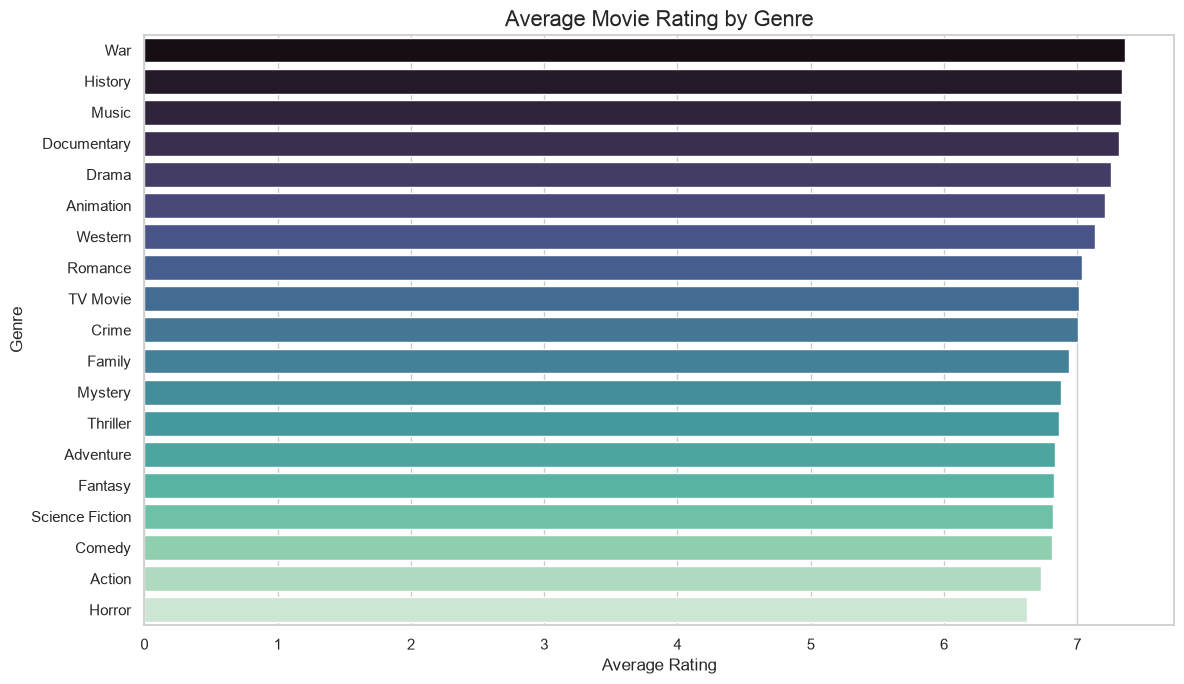

In [12]:
# Merge movie genres with movie ratings
genre_ratings = movie_genres_df.merge(
    genres_df,
    on="genre_id",
    how="left"
).merge(
    movies_df[["movie_id", "vote_average"]],
    on="movie_id",
    how="inner"
)

# Calculate average rating for each genre
average_genre_rating = (
    genre_ratings.groupby("genre_name")["vote_average"]
    .mean()
    .sort_values(ascending=False)
)

# Plot
plt.figure(figsize=(12, 7))

sns.barplot(
    x=average_genre_rating.values,
    y=average_genre_rating.index,
    hue=average_genre_rating.index,
    palette="mako",
    legend=False
)

plt.title("Average Movie Rating by Genre", fontsize=16)
plt.xlabel("Average Rating")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

### Insights

- War has the highest average movie rating, followed closely by History and Music.
- Drama, Documentary and Animation also receive relatively high average ratings.
- Horror has the lowest average rating, followed by Action and Comedy.
- Most genres have average ratings between 6.6 and 7.4.
- The difference between the highest- and lowest-rated genres is relatively small.

### Conclusion

Audience ratings are relatively consistent across genres, although War, History and Music perform slightly better on average than Horror, Action and Comedy.

## 9: Number of Movies Released per Year

**Objective:** To analyse how movie production has changed over the years.

**Chart:** Column chart.

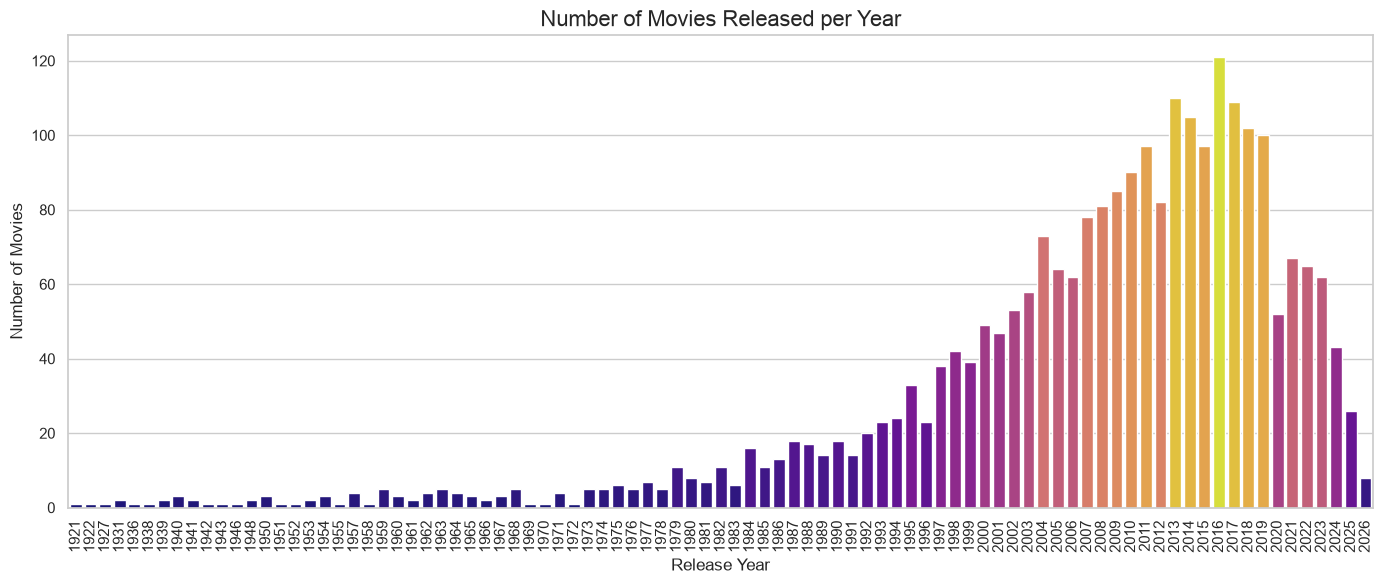

In [13]:
# Extract release year
movies_df["release_year"] = movies_df["release_date"].dt.year

# Count movies released each year
yearly_movies = (
    movies_df.groupby("release_year")["movie_id"]
    .nunique()
    .reset_index(name="movie_count")
)

# Plot
plt.figure(figsize=(14, 6))

sns.barplot(
    data=yearly_movies,
    x="release_year",
    y="movie_count",
    hue="movie_count",
    palette="plasma",
    legend=False
)

plt.title("Number of Movies Released per Year", fontsize=16)
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

### Insights

- Movie releases were relatively low during the early decades, with only a few movies released each year.
- The number of movie releases started increasing noticeably from the 1980s.
- Movie production grew significantly during the 1990s and 2000s.
- **2016 recorded the highest number of releases**, with approximately 121 movies.
- After 2019, the number of releases declined, with a noticeable drop around 2020.
- The dataset shows fewer recent releases, particularly from 2024 onwards.

### Conclusion

Movie production increased substantially over the decades, reaching its highest point in 2016. The decline in recent years may partly reflect the dataset's coverage and release-date availability.

## 10: Top 10 Highest-Grossing Movies

**Objective:** To identify the movies that generated the highest worldwide revenue.

**Chart:** Horizontal bar chart.

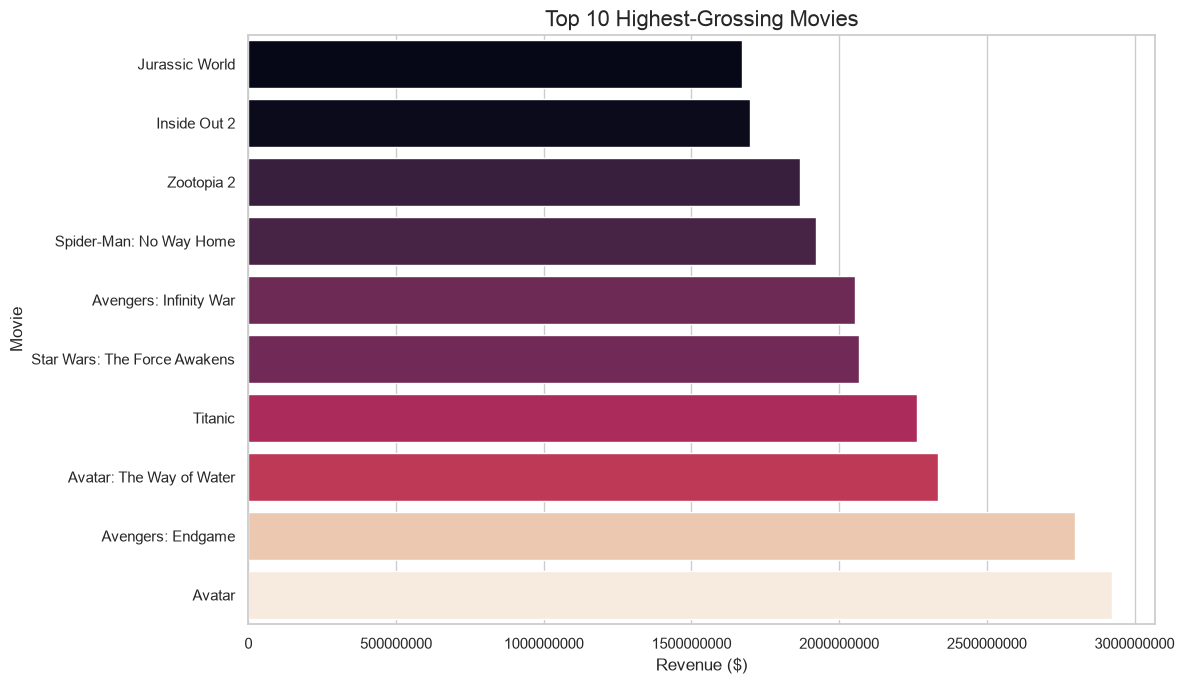

In [14]:
# Select movies with valid revenue
top_revenue_movies = (
    original_movies_df[
        original_movies_df["revenue"] > 0
    ]
    .nlargest(10, "revenue")
    .sort_values("revenue", ascending=True)
)

# Plot
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_revenue_movies,
    x="revenue",
    y="title",
    hue="revenue",
    palette="rocket",
    legend=False
)

plt.title("Top 10 Highest-Grossing Movies", fontsize=16)
plt.xlabel("Revenue ($)")
plt.ylabel("Movie")

plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

### Insights

- **Avatar** is the highest-grossing movie in the dataset, generating approximately $2.92 billion.
- **Avengers: Endgame** ranks second, with approximately $2.8 billion in revenue.
- Avatar: The Way of Water and Titanic also generated more than $2 billion.
- The top 10 list is dominated by major franchise films and large-scale productions.
- Jurassic World and Inside Out 2 complete the lower end of the top 10, with revenues of approximately $1.7 billion each.

### Conclusion

A small group of blockbuster movies generate exceptionally high worldwide revenues, with Avatar and Avengers: Endgame leading the dataset.

## 11: Top 10 Movies by ROI

**Objective:** To identify movies that generated the highest return on investment relative to their production budgets.

**Chart:** Horizontal bar chart.

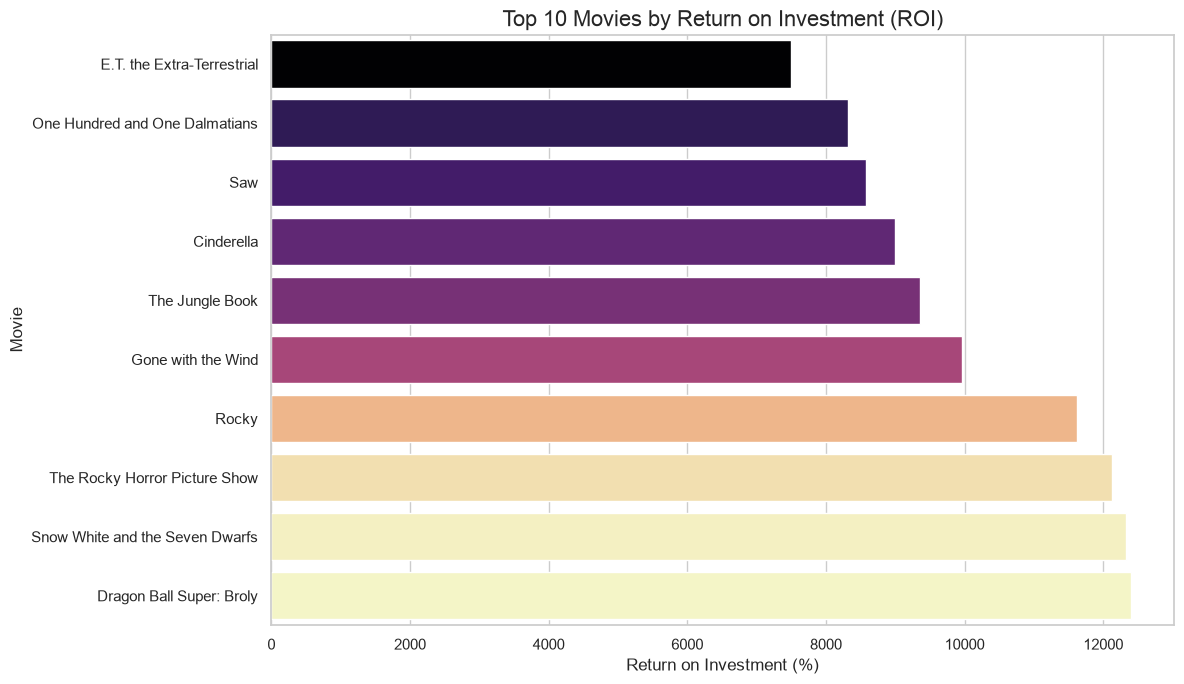

In [15]:
# Calculate ROI using valid original budget and revenue values
roi_movies = original_movies_df[
    (original_movies_df["budget"] >= 1_000_000) &
    (original_movies_df["revenue"] > 0)
].copy()

roi_movies["ROI"] = (
    (roi_movies["revenue"] - roi_movies["budget"])
    / roi_movies["budget"]
) * 100

# Select top 10 movies
top_roi_movies = (
    roi_movies.nlargest(10, "ROI")
    .sort_values("ROI", ascending=True)
)

# Plot
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_roi_movies,
    x="ROI",
    y="title",
    hue="ROI",
    palette="magma",
    legend=False
)

plt.title("Top 10 Movies by Return on Investment (ROI)", fontsize=16)
plt.xlabel("Return on Investment (%)")
plt.ylabel("Movie")

plt.tight_layout()
plt.show()

### Insights

- **Dragon Ball Super: Broly** recorded the highest ROI at approximately 12,400%.
- **Snow White and the Seven Dwarfs** and **The Rocky Horror Picture Show** also achieved ROI values above 12,000%.
- Rocky and Gone with the Wind generated exceptionally high returns compared to their production budgets.
- Even E.T. the Extra-Terrestrial, which ranks tenth, achieved an ROI of approximately 7,500%.
- Older movies feature prominently among the highest-ROI films.

### Conclusion

Several movies generated exceptionally high returns relative to their production budgets. However, ROI considers only production budget and revenue, excluding marketing, distribution and other expenses.

## 12: Correlation Heatmap

**Objective:** To examine the relationships between important numerical movie attributes.

**Chart:** Correlation heatmap.

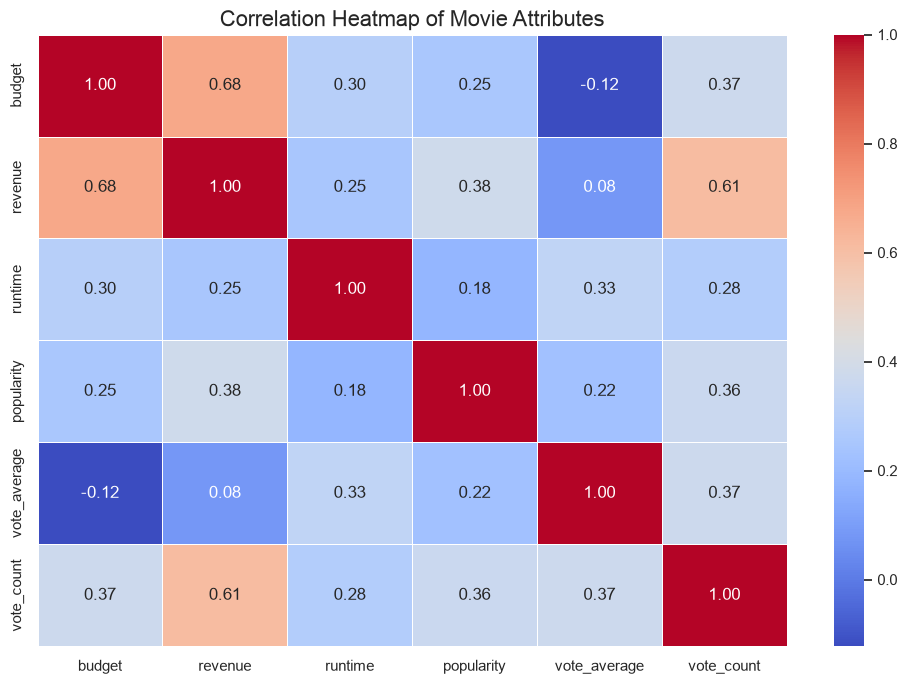

In [16]:
# Select numerical columns
correlation_data = movies_df[
    [
        "budget",
        "revenue",
        "runtime",
        "popularity",
        "vote_average",
        "vote_count"
    ]
]

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Movie Attributes", fontsize=16)
plt.tight_layout()
plt.show()

### Insights

- Budget and revenue have a strong positive correlation of **0.68**, suggesting that higher-budget movies generally tend to generate higher revenue.
- Revenue and vote count show a moderately strong positive correlation of **0.61**.
- Popularity and revenue have a moderate positive correlation of **0.38**.
- Popularity and vote count have a positive correlation of **0.36**.
- Runtime and vote average show a positive correlation of **0.33**.
- Budget and vote average have a slight negative correlation of **-0.12**, indicating almost no meaningful linear relationship.

### Conclusion

Movie budget has the strongest relationship with revenue, while vote count is also positively associated with revenue. However, most other variables show relatively weak or moderate correlations, suggesting that no single attribute fully explains a movie's performance.

## 13: Budget vs Revenue by Genre

**Objective:** To examine how budget and revenue vary across different primary genres.

**Chart:** Multivariate scatter plot.

In [17]:
# Identify each movie's primary genre
primary_genres = movie_genres_df.drop_duplicates(
    subset="movie_id",
    keep="first"
)

# Merge genre names and movie details
genre_financial_data = (
    original_movies_df.merge(
        primary_genres,
        on="movie_id",
        how="inner"
    )
    .merge(
        genres_df,
        on="genre_id",
        how="left"
    )
)

# Keep valid financial values
genre_financial_data = genre_financial_data[
    (genre_financial_data["budget"] > 0) &
    (genre_financial_data["revenue"] > 0) &
    (genre_financial_data["vote_count"] > 0)
]

# Interactive scatter plot
fig = px.scatter(
    genre_financial_data,
    x="budget",
    y="revenue",
    color="genre_name",
    size="vote_count",
    hover_name="title",
    title="Movie Budget vs Revenue by Primary Genre",
    labels={
        "budget": "Budget ($)",
        "revenue": "Revenue ($)",
        "genre_name": "Primary Genre",
        "vote_count": "Vote Count"
    },
    opacity=0.7
)

fig.update_layout(
    width=1100,
    height=700
)

fig.show()

### Insights

- Most movies across genres are concentrated in the lower budget and revenue ranges.
- Adventure and Action movies include several of the highest-revenue productions.
- Science Fiction and Animation also contain movies with relatively high revenues.
- Some movies generate substantial revenue despite having moderate production budgets.
- Larger bubbles represent movies with higher vote counts, showing that several major box-office performers also attract considerable audience engagement.
- Movies within the same genre show considerable variation in revenue, suggesting that genre alone does not determine financial success.

### Conclusion

High-budget movies often generate higher revenues, particularly in genres such as Action and Adventure. However, successful movies can be found across multiple genres and budget levels.

## 14: Average Revenue by Genre and Release Decade

**Objective:** To compare average movie revenue across different genres and release decades.

**Chart:** Heatmap.

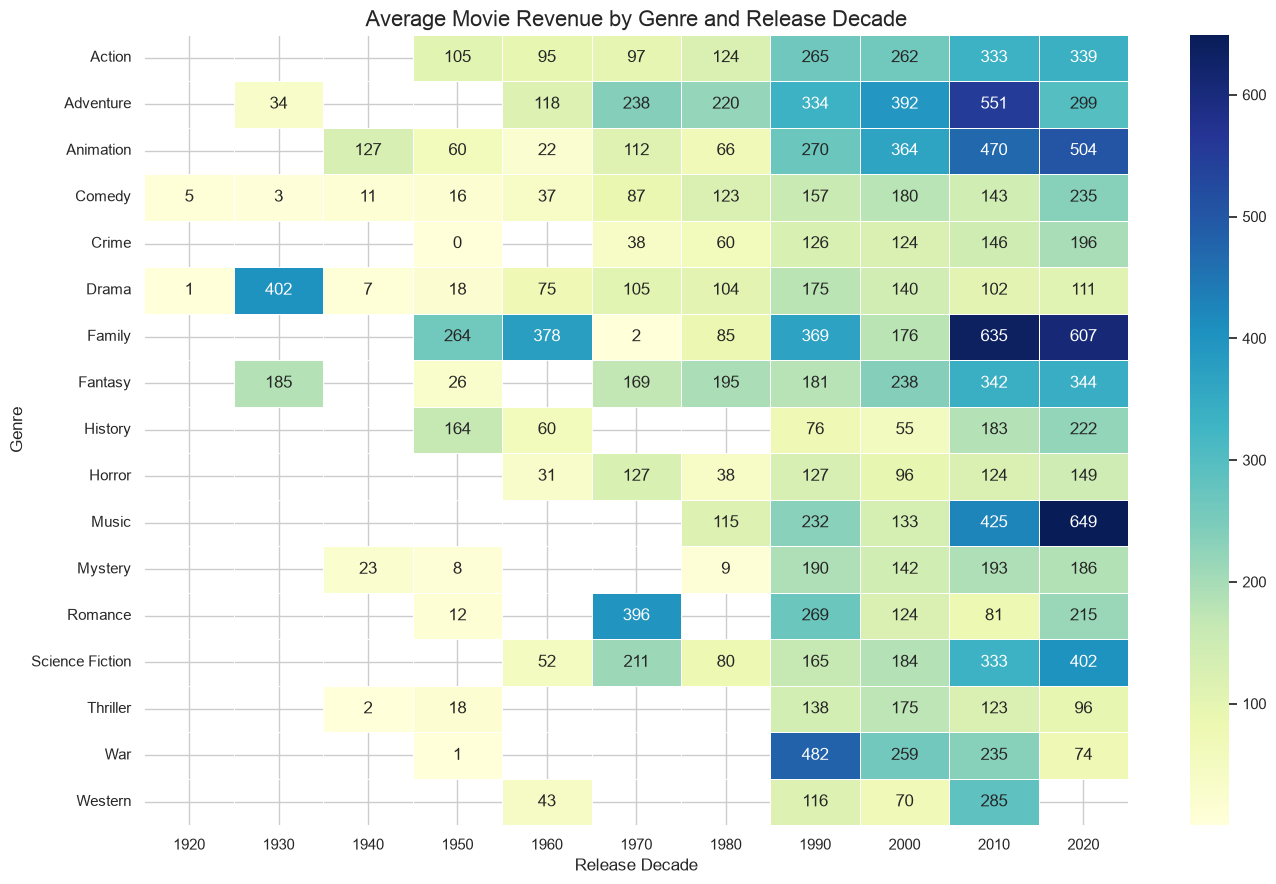

In [18]:
# Add release year and decade
genre_decade_data = genre_financial_data.copy()

genre_decade_data["release_year"] = pd.to_datetime(
    genre_decade_data["release_date"],
    errors="coerce"
).dt.year

genre_decade_data = genre_decade_data.dropna(
    subset=["release_year"]
)

genre_decade_data["release_decade"] = (
    (genre_decade_data["release_year"] // 10) * 10
).astype(int)

# Calculate average revenue by genre and decade
revenue_pivot = genre_decade_data.pivot_table(
    index="genre_name",
    columns="release_decade",
    values="revenue",
    aggfunc="mean"
) / 1_000_000

# Create heatmap
plt.figure(figsize=(14, 9))

sns.heatmap(
    revenue_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Average Movie Revenue by Genre and Release Decade", fontsize=16)
plt.xlabel("Release Decade")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

### Insights

- Action and Adventure movies show strong revenue performance in recent decades.
- Family movies recorded particularly high average revenues in the 2010s and 2020s.
- Music movies achieved the highest average revenue in the 2020s, at approximately $649 million.
- Adventure movies reached an average revenue of approximately $551 million in the 2010s.
- Animation movies also show strong revenue growth in recent decades.
- Older decades contain fewer observations for several genres, so their average revenues should be interpreted cautiously.

### Conclusion

Family, Music, Adventure and Animation movies show strong average revenue performance in recent decades. Revenue patterns vary considerably across genres and release periods.

## 15: Movie Rating Distribution by Genre

**Objective:** To compare how movie ratings are distributed across different genres.

**Chart:** FacetGrid with histograms.

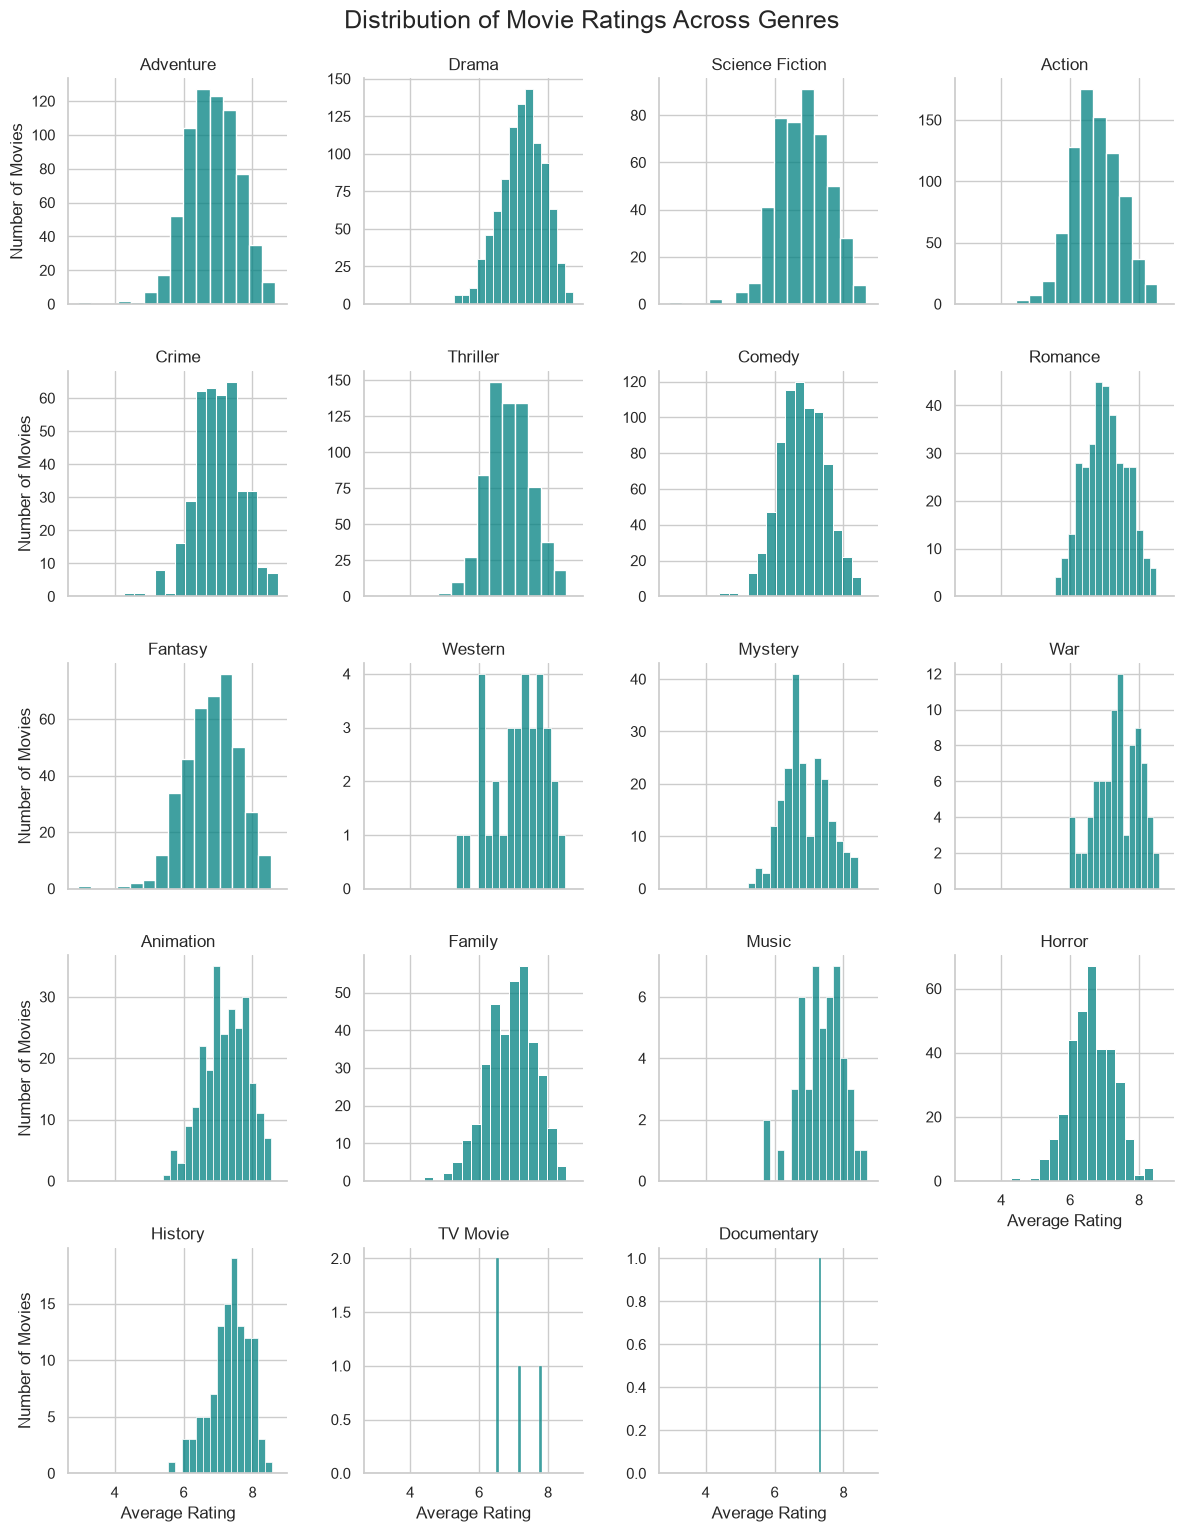

In [19]:
# Prepare movie ratings with genre names
rating_genre_data = movie_genres_df.merge(
    genres_df,
    on="genre_id",
    how="left"
).merge(
    movies_df[["movie_id", "vote_average"]],
    on="movie_id",
    how="inner"
)

# Create FacetGrid
g = sns.FacetGrid(
    rating_genre_data,
    col="genre_name",
    col_wrap=4,
    height=3,
    sharex=True,
    sharey=False
)

g.map_dataframe(
    sns.histplot,
    x="vote_average",
    bins=15,
    color="teal"
)

g.set_axis_labels("Average Rating", "Number of Movies")
g.set_titles("{col_name}")

g.fig.suptitle(
    "Distribution of Movie Ratings Across Genres",
    fontsize=18,
    y=1.02
)

plt.show()

### Insights

- Most genres show rating distributions concentrated between 6 and 8.
- Drama, Adventure, Action and Comedy have relatively large numbers of movies with ratings around 6.5–7.5.
- War, History and Music show ratings concentrated towards the higher end, although these genres have fewer movies.
- Horror movies are mostly concentrated around ratings 6–7.
- Western, TV Movie and Documentary have fewer observations, resulting in less detailed distributions.
- The overall rating patterns are relatively similar across most major genres.

### Conclusion

Most genres receive moderate to good audience ratings, generally concentrated between 6 and 8. However, the number of movies available in each genre varies considerably, so distributions from smaller genres should be interpreted cautiously.